<a href="https://colab.research.google.com/github/Anjali-Negi29/ChatBot/blob/main/ResumeScreening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("All libraries are ready!")


All libraries are ready!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

resumes = [
    """
    Candidate A. Software engineering intern.
    Skills: Python, Java, SQL, machine learning,
    data analysis, pandas, scikit-learn.
    """

    ,
    """
    Candidate B. Backend developer.
    Skills: Java, SQL, Spring Boot, databases,
    REST APIs, software development.
    """

    ,
    """
    Candidate C. Frontend developer.
    Skills: HTML, CSS, JavaScript, React,
    responsive design, web development.
    """
]

job_description = """
We are looking for a machine learning intern
with Python, SQL, data analysis, machine learning,
pandas, scikit-learn and programming skills.
"""

print("Number of sample resumes:", len(resumes))
print("\nJob description:")
print(job_description)


Number of sample resumes: 3

Job description:

We are looking for a machine learning intern
with Python, SQL, data analysis, machine learning,
pandas, scikit-learn and programming skills.



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

documents = resumes + [job_description]

vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF matrix created successfully!")
print("Shape:", tfidf_matrix.shape)

TF-IDF matrix created successfully!
Shape: (4, 33)


In [ ]:
resume_vectors = tfidf_matrix[:len(resumes)]
job_vector = tfidf_matrix[len(resumes):]

similarity_scores = cosine_similarity(
    resume_vectors,
    job_vector
).flatten()

results = pd.DataFrame({
    "Candidate": ["Candidate A", "Candidate B", "Candidate C"],
    "Similarity Score (%)": (similarity_scores * 100).round(2)
})

results = results.sort_values(
    by="Similarity Score (%)",
    ascending=False
)

print(results.to_string(index=False))

  Candidate  Similarity Score (%)
Candidate A                 72.63
Candidate B                  6.34
Candidate C                  2.50


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving Resume.csv to Resume.csv


In [ ]:

import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (2484, 4)

First 5 rows:


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR



Column names:
['ID', 'Resume_str', 'Resume_html', 'Category']


In [ ]:
print(df["Category"].value_counts())

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [ ]:
print("DATASET SHAPE:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nFIRST 5 RECORDS:")
display(df.head())

print("\nCATEGORY COLUMN CHECK:")

if "Category" in df.columns:
    print("Category column exists.")
    print("Non-empty categories:", df["Category"].notna().sum())
    print("Unique categories:", df["Category"].nunique())
    print(df["Category"].value_counts(dropna=False).head(20))
else:
    print("Category column does not exist.")

DATASET SHAPE: (2484, 4)

COLUMN NAMES:
['ID', 'Resume_str', 'Resume_html', 'Category']

FIRST 5 RECORDS:


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR



CATEGORY COLUMN CHECK:
Category column exists.
Non-empty categories: 2484
Unique categories: 24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
Name: count, dtype: int64


In [ ]:

from google.colab import files
import pandas as pd
import io

print("Please upload your original CSV dataset")

uploaded = files.upload()

filename = next(iter(uploaded))

raw_df = pd.read_csv(io.BytesIO(uploaded[filename]))

raw_df.columns = raw_df.columns.str.strip()

print("\nDataset recovered successfully!")
print("Shape:", raw_df.shape)

display(raw_df.head())


Please upload your original CSV dataset


Saving Resume.csv to Resume (1).csv

Dataset recovered successfully!
Shape: (2484, 4)


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [ ]:
# Extract all unique categories
all_categories = raw_df["Category"].dropna().unique()

print("TOTAL UNIQUE CATEGORIES:", len(all_categories))

print("\nALL RESUME CATEGORIES:")

for i, category in enumerate(sorted(all_categories), start=1):
    print(i, category)

TOTAL UNIQUE CATEGORIES: 24

ALL RESUME CATEGORIES:
1 ACCOUNTANT
2 ADVOCATE
3 AGRICULTURE
4 APPAREL
5 ARTS
6 AUTOMOBILE
7 AVIATION
8 BANKING
9 BPO
10 BUSINESS-DEVELOPMENT
11 CHEF
12 CONSTRUCTION
13 CONSULTANT
14 DESIGNER
15 DIGITAL-MEDIA
16 ENGINEERING
17 FINANCE
18 FITNESS
19 HEALTHCARE
20 HR
21 INFORMATION-TECHNOLOGY
22 PUBLIC-RELATIONS
23 SALES
24 TEACHER


In [ ]:
category_counts = (
    raw_df["Category"]
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
)

print("NUMBER OF RESUMES IN EACH CATEGORY:")

display(
    category_counts.reset_index().rename(
        columns={
            "Category": "Resume Category",
            "count": "Number of Resumes"
        }
    )
)

print("\nTotal resumes counted:", category_counts.sum())

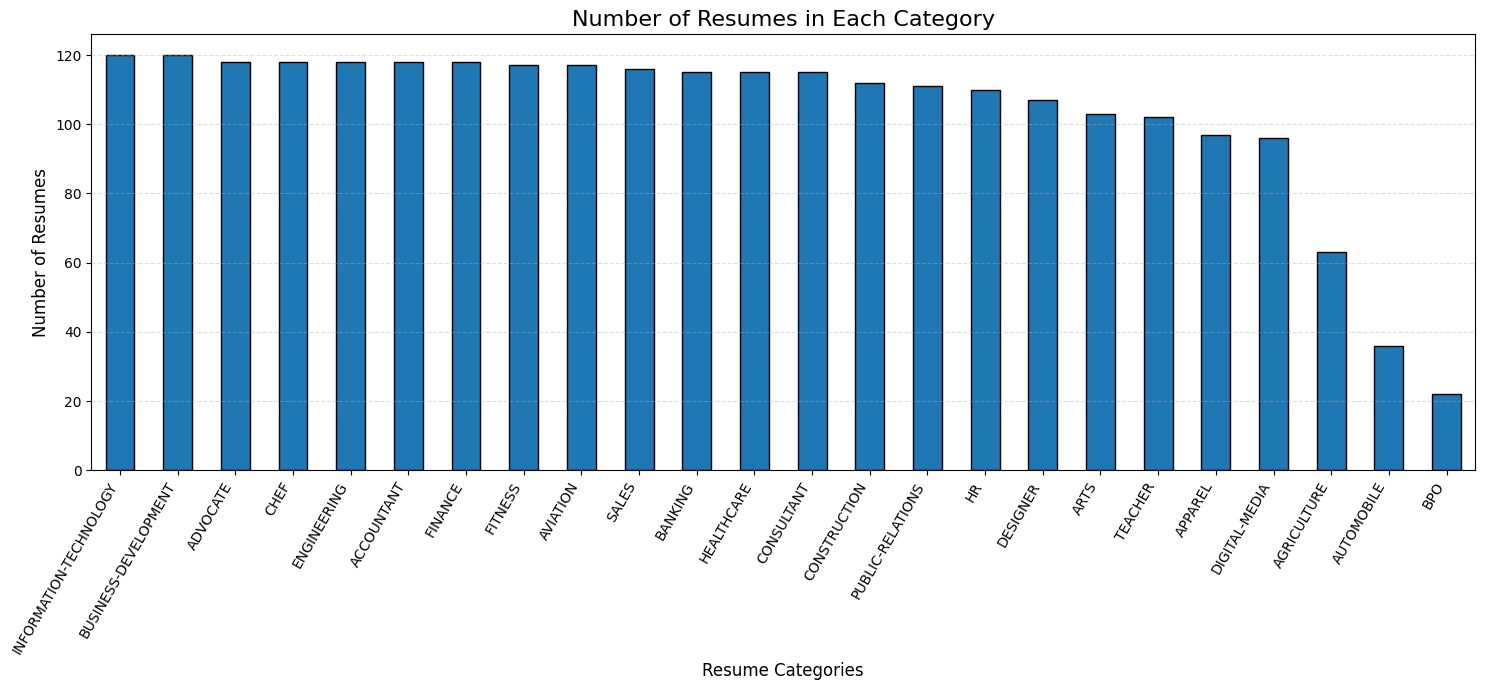

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

category_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title(
    "Number of Resumes in Each Category",
    fontsize=16
)

plt.xlabel("Resume Categories", fontsize=12)
plt.ylabel("Number of Resumes", fontsize=12)

plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
category_counts.to_csv(
    "resume_category_statistics.csv",
    header=["Number_of_Resumes"]
)

print("Category statistics saved successfully!")

files.download("resume_category_statistics.csv")

Category statistics saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()


In [ ]:

import re
import pandas as pd

TEXT_COLUMNS = [
    "career_objective",
    "skills",
    "degree_names",
    "major_field_of_studies",
    "positions",
    "responsibilities"
]

available_columns = [
    col for col in TEXT_COLUMNS if col in df.columns
]

print("Columns used:", available_columns)

def combine_resume(row):
    values = []

    for col in available_columns:
        value = row[col]

        if pd.notna(value):
            value = str(value).strip()

            if value and value.lower() != "nan":
                values.append(value)

    return " ".join(values)


df["Resume"] = df.apply(combine_resume, axis=1)

df = df[
    df["Resume"].str.strip().ne("")
].copy()

def clean_resume(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9+#.\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Cleaned_Resume"] = df["Resume"].apply(clean_resume)

print("Resume text created successfully!")
print("Total resumes:", len(df))

display(df[["Resume", "Cleaned_Resume"]].head())


In [ ]:
print(df.columns.tolist())

print("\nNon-empty values in each column:")
print(df.notna().sum().sort_values(ascending=False))

In [ ]:

!pip -q install pymupdf python-docx


In [ ]:
from google.colab import files

uploaded_resumes = files.upload()

print("Files uploaded:", list(uploaded_resumes.keys()))

Saving My Resume.pdf to My Resume (1).pdf
Files uploaded: ['My Resume (1).pdf']


In [ ]:

import fitz  # PyMuPDF
from docx import Document
import io
import os
import pandas as pd

def extract_pdf_text(file_bytes):
    text_parts = []

    with fitz.open(
        stream=file_bytes,
        filetype="pdf"
    ) as pdf:
        for page in pdf:
            text_parts.append(page.get_text())

    return "\n".join(text_parts)


def extract_docx_text(file_bytes):
    document = Document(io.BytesIO(file_bytes))

    parts = [p.text for p in document.paragraphs]

    for table in document.tables:
        for row in table.rows:
            parts.append(
                " ".join(cell.text for cell in row.cells)
            )

    return "\n".join(parts)


def extract_resume_text(filename, file_bytes):
    extension = os.path.splitext(filename)[1].lower()

    if extension == ".pdf":
        return extract_pdf_text(file_bytes)

    elif extension == ".docx":
        return extract_docx_text(file_bytes)

    else:
        raise ValueError(
            f"Unsupported file format: {extension}"
        )


In [ ]:

resume_records = []

for filename, file_bytes in uploaded_resumes.items():
    try:
        extracted_text = extract_resume_text(
            filename,
            file_bytes
        )

        resume_records.append({
            "Filename": filename,
            "Resume_Text": extracted_text,
            "Cleaned_Resume": clean_resume(extracted_text)
        })

        print(
            f"Extracted: {filename} | "
            f"Characters: {len(extracted_text)}"
        )

    except Exception as e:
        print(f"Error reading {filename}: {e}")

resumes_df = pd.DataFrame(resume_records)

print("\nTotal resumes processed:", len(resumes_df))
display(resumes_df[["Filename", "Cleaned_Resume"]].head())


In [ ]:
import pandas as pd
import io
import os
import fitz
from docx import Document

resume_records = []

for filename, file_bytes in uploaded_resumes.items():
    try:
        ext = os.path.splitext(filename)[1].lower()

        if ext == ".pdf":
            with fitz.open(
                stream=file_bytes,
                filetype="pdf"
            ) as pdf:
                text = "\n".join(
                    page.get_text() for page in pdf
                )

        elif ext == ".docx":
            doc = Document(io.BytesIO(file_bytes))
            text = "\n".join(
                p.text for p in doc.paragraphs
            )

        else:
            print("Unsupported file:", filename)
            continue

        resume_records.append({
            "Filename": filename,
            "Resume_Text": text
        })

        print("Processed:", filename)

    except Exception as e:
        print("Error:", filename, e)

resumes_df = pd.DataFrame(resume_records)

print("DataFrame created!")
print("Total resumes:", len(resumes_df))

In [ ]:

if resumes_df.empty:
    print("No resumes were successfully processed.")
else:
    resumes_df["Text_Length"] = (
        resumes_df["Resume_Text"].str.len()
    )

    display(
        resumes_df[["Filename", "Text_Length"]]
    )

    for _, row in resumes_df.iterrows():
        print("\nResume:", row["Filename"])
        print(row["Resume_Text"][:500])
        print("-" * 50)


In [ ]:

output_file = "processed_resumes.csv"

resumes_df.to_csv(output_file, index=False)

print("Processed dataset saved:", output_file)

files.download(output_file)


In [ ]:

if "raw_df" in globals() and len(raw_df) > 0:
    candidate_df = raw_df.copy()

elif "df" in globals() and len(df) > 0:
    candidate_df = df.copy()

else:
    print("Original dataset not found.")
    print("Please reload your original 2,484-row CSV.")

if "candidate_df" in globals():
    print("Dataset loaded successfully!")
    print("Dataset shape:", candidate_df.shape)

    print("\nAvailable columns:")
    print(candidate_df.columns.tolist())

    print("\nFirst 5 candidate records:")
    display(candidate_df.head())


Dataset loaded successfully!
Dataset shape: (2484, 4)

Available columns:
['ID', 'Resume_str', 'Resume_html', 'Category']

First 5 candidate records:


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [ ]:
print("Uploaded reference resumes:")

for filename in uploaded_resumes.keys():
    print(filename)

Uploaded reference resumes:
My Resume (1).pdf


In [ ]:
import fitz
import io
import os
from docx import Document

reference_filename = list(uploaded_resumes.keys())[0]

file_bytes = uploaded_resumes[reference_filename]

extension = os.path.splitext(reference_filename)[1].lower()

if extension == ".pdf":

    with fitz.open(
        stream=file_bytes,
        filetype="pdf"
    ) as pdf:

        reference_resume_text = "\n".join(
            page.get_text() for page in pdf
        )

elif extension == ".docx":

    document = Document(io.BytesIO(file_bytes))

    reference_resume_text = "\n".join(
        paragraph.text
        for paragraph in document.paragraphs
    )

else:
    raise ValueError("Upload a PDF or DOCX resume.")

print("Reference resume extracted successfully!")
print("Filename:", reference_filename)
print("Characters extracted:", len(reference_resume_text))

Reference resume extracted successfully!
Filename: My Resume (1).pdf
Characters extracted: 918


In [ ]:
print("REFERENCE RESUME CONTENT")
print("-" * 50)

print(reference_resume_text[:1500])

REFERENCE RESUME CONTENT
--------------------------------------------------
Experience
Internshala | Dehradun, Uttarakhand
Internship Student | 06/2026 - 08/2026
Created full stack project DefensePrep as my course was Full stack web development with AI
It is a website that is used for preparation of defense exams which provides every resource at one place .
Skills
Communication skills, Time management, Leadership, Microsoft word, Problem solving | Public Presentation
Education
Uttaranchal University | Dehradun, Uttarakhand
B.Tech CSE | 06/2028
I am a Computer Science student - 8.5+/10 GPA
Core Technical Stack: Java, Python, JavaScript, Node.js, PHP, HTML5, CSS3
Key achievements: - Ranked 2nd in Modelling show at Uttaranchal University out of all departments/colleges. -NCC
Cadet(Sergeant Rank): Demonstrated leadership in discipline and teamwork and have done Army Attachment Camp -Active
Hackathon Competitor
Anjali Negi
9607614029 | anjalinegi2906@gmail.com | Dehradun, Uttarakhand



In [ ]:
import re

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+|www\S+", " ", text)

    text = re.sub(r"\S+@\S+", " ", text)

    text = re.sub(
        r"[^a-z0-9+#.\s]",
        " ",
        text
    )

    text = re.sub(r"\s+", " ", text)

    return text.strip()


reference_cleaned = clean_text(reference_resume_text)

print("Reference resume cleaned successfully!")
print("Cleaned characters:", len(reference_cleaned))

print("\nCleaned resume preview:")
print(reference_cleaned[:1000])

Reference resume cleaned successfully!
Cleaned characters: 853

Cleaned resume preview:
experience internshala dehradun uttarakhand internship student 06 2026 08 2026 created full stack project defenseprep as my course was full stack web development with ai it is a website that is used for preparation of defense exams which provides every resource at one place . skills communication skills time management leadership microsoft word problem solving public presentation education uttaranchal university dehradun uttarakhand b.tech cse 06 2028 i am a computer science student 8.5+ 10 gpa core technical stack java python javascript node.js php html5 css3 key achievements ranked 2nd in modelling show at uttaranchal university out of all departments colleges. ncc cadet sergeant rank demonstrated leadership in discipline and teamwork and have done army attachment camp active hackathon competitor anjali negi 9607614029 dehradun uttarakhand


In [ ]:
print("Candidate dataset shape:", candidate_df.shape)

print("\nAvailable columns:")
print(candidate_df.columns.tolist())

print("\nSample candidate records:")
display(candidate_df.head(3))

Candidate dataset shape: (2484, 4)

Available columns:
['ID', 'Resume_str', 'Resume_html', 'Category']

Sample candidate records:


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [ ]:
if "Resume_str" in candidate_df.columns:
    TEXT_COLUMN = "Resume_str"

elif "Resume" in candidate_df.columns:
    TEXT_COLUMN = "Resume"

elif "Cleaned_Resume" in candidate_df.columns:
    TEXT_COLUMN = "Cleaned_Resume"

else:
    raise ValueError("No suitable resume text column found!")

print("Selected resume column:", TEXT_COLUMN)

processed_candidates = candidate_df.copy()


processed_candidates = processed_candidates.dropna(
    subset=[TEXT_COLUMN]
).copy()


processed_candidates[TEXT_COLUMN] = (
    processed_candidates[TEXT_COLUMN].astype(str)
)



processed_candidates["Cleaned_Resume"] = (
    processed_candidates[TEXT_COLUMN].apply(clean_text)
)


processed_candidates = processed_candidates[
    processed_candidates["Cleaned_Resume"].str.len() > 0
].copy()

processed_candidates.reset_index(
    drop=True,
    inplace=True
)

print("\nCandidate preprocessing completed!")
print("Original candidates:", len(candidate_df))
print("Usable candidates:", len(processed_candidates))

Selected resume column: Resume_str

Candidate preprocessing completed!
Original candidates: 2484
Usable candidates: 2483


In [ ]:
print("Processed dataset shape:")
print(processed_candidates.shape)

print("\nSample processed resumes:")

display(
    processed_candidates[
        [TEXT_COLUMN, "Cleaned_Resume"]
    ].head(3)
)

Processed dataset shape:
(2483, 5)

Sample processed resumes:


,Resume_str,Cleaned_Resume
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,hr administrator marketing associate hr admini...
1,"HR SPECIALIST, US HR OPERATIONS ...",hr specialist us hr operations summary versati...
2,HR DIRECTOR Summary Over 2...,hr director summary over 20 years experience i...


In [ ]:
if "Category" in processed_candidates.columns:

    print("Available candidate categories:")

    print(
        processed_candidates["Category"]
        .value_counts()
    )

else:
    print("Category column not available.")

Available candidate categories:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [ ]:
all_resumes = (
    processed_candidates["Cleaned_Resume"].tolist()
    + [reference_cleaned]
)

print("Total documents:", len(all_resumes))
print("Candidate resumes:", len(processed_candidates))
print("Reference resumes:", 1)

Total documents: 2484
Candidate resumes: 2483
Reference resumes: 1


In [ ]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(all_resumes)

print("TF-IDF conversion completed!")
print("Matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

TF-IDF conversion completed!
Matrix shape: (2484, 10000)
Vocabulary size: 10000


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

candidate_vectors = tfidf_matrix[:-1]

reference_vector = tfidf_matrix[-1:]

print("Candidate vectors:", candidate_vectors.shape)
print("Reference vector:", reference_vector.shape)


Candidate vectors: (2483, 10000)
Reference vector: (1, 10000)


In [ ]:
similarity_scores = cosine_similarity(
    candidate_vectors,
    reference_vector
).flatten()

print("Similarity calculation completed!")
print("Total candidates compared:", len(similarity_scores))

Similarity calculation completed!
Total candidates compared: 2483


In [ ]:
processed_candidates["Similarity_Score"] = (
    similarity_scores * 100
).round(2)

print("Similarity scores added successfully!")

display(
    processed_candidates[
        ["ID", "Category", "Similarity_Score"]
    ].head(10)
)

Similarity scores added successfully!


,ID,Category,Similarity_Score
0,16852973,HR,3.20
1,22323967,HR,2.96
2,33176873,HR,6.00
3,27018550,HR,3.17
4,17812897,HR,3.75
5,11592605,HR,5.62
6,25824789,HR,4.49
7,15375009,HR,2.04
8,11847784,HR,3.71
9,32896934,HR,3.60


In [ ]:
ranked_candidates = processed_candidates.sort_values(
    by="Similarity_Score",
    ascending=False
).reset_index(drop=True)

ranked_candidates.insert(
    0,
    "Rank",
    range(1, len(ranked_candidates) + 1)
)

display(
    ranked_candidates[
        ["Rank", "ID", "Category", "Similarity_Score"]
    ].head(20)
)

,Rank,ID,Category,Similarity_Score
0,1,83816738,INFORMATION-TECHNOLOGY,15.07
1,2,33141415,CONSTRUCTION,15.03
2,3,22351830,CONSULTANT,14.32
3,4,28505854,ENGINEERING,14.19
4,5,21511817,CHEF,12.06
5,6,12144825,AVIATION,11.61
6,7,10641230,INFORMATION-TECHNOLOGY,11.21
7,8,23464505,AVIATION,11.20
8,9,24643412,CONSULTANT,10.94
9,10,11522068,FITNESS,10.90


In [ ]:
THRESHOLD = 40

shortlisted_candidates = ranked_candidates[
    ranked_candidates["Similarity_Score"] >= THRESHOLD
].copy()

print("Total candidates:", len(ranked_candidates))
print("Shortlisted candidates:", len(shortlisted_candidates))
print("Not shortlisted:", len(ranked_candidates) - len(shortlisted_candidates))

Total candidates: 2483
Shortlisted candidates: 0
Not shortlisted: 2483


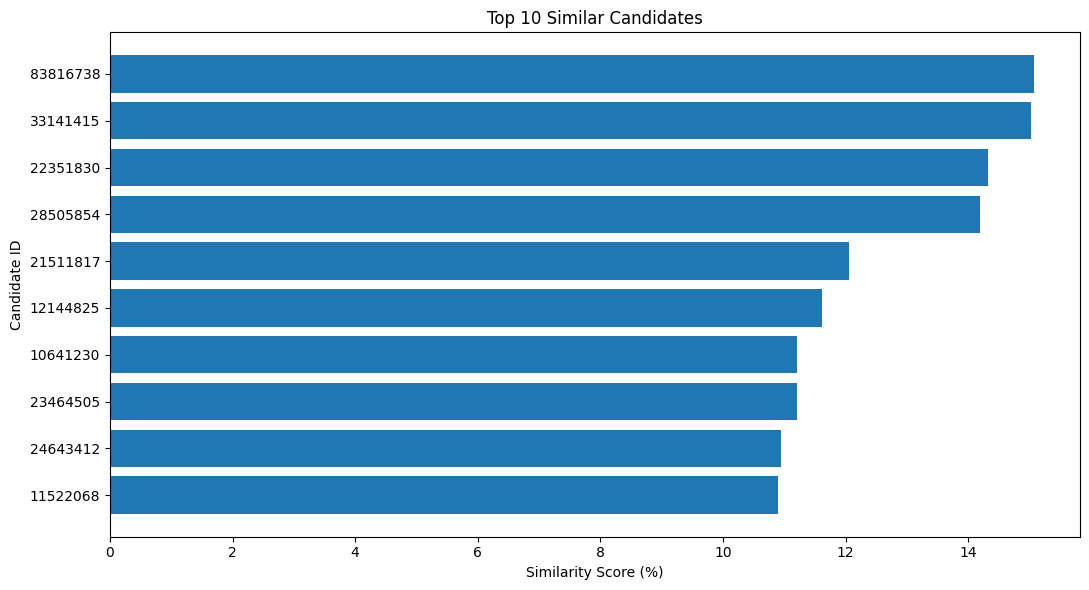

In [ ]:
import matplotlib.pyplot as plt

top_10 = ranked_candidates.head(10).copy()

plt.figure(figsize=(11, 6))

plt.barh(
    top_10["ID"].astype(str),
    top_10["Similarity_Score"]
)

plt.xlabel("Similarity Score (%)")
plt.ylabel("Candidate ID")
plt.title("Top 10 Similar Candidates")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
output_file = "final_shortlisted_candidates.csv"

shortlisted_candidates.to_csv(
    output_file,
    index=False
)

from google.colab import files

files.download(output_file)

print("Shortlist exported successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Shortlist exported successfully!
